In [4]:
from kaggle.api.kaggle_api_extended import KaggleApi
import os
import sys
import zipfile
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.base import BaseEstimator, clone
from sklearn.utils.metaestimators import _safe_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import RidgeCV, QuantileRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
import plotly.express as px
import plotly.graph_objects as go


_PATH = Path.cwd()

# 1. Introduction

L'Ã©lectricitÃ© est nÃ©gociÃ©e sur plusieurs marchÃ©s Ã  Ã©chÃ©ances diffÃ©rentes :

- MarchÃ© spot : l'Ã©lectricitÃ© y est nÃ©gociÃ©e Ã  Ã©chÃ©ance d'un jour :
  - Day-ahead : enchÃ¨res journaliÃ¨res pour le lendemain, via l'EPEX par exemple
  - Intraday : marchÃ© continu ajustant les positions peu de temps avant la livraison rÃ©elle (jusqu'Ã  5 minutes avant)
- MarchÃ© Ã  terme : NÃ©gociÃ© sur l'EEX par exemple, positions plus longues permettant notamment pour les industriels de se hedger face Ã  la volatilitÃ© spot.
- MarchÃ© "physique" : marchÃ© dont les sous-jacents sont les moyens de production (centrales nuclÃ©aires, thermiques ...) et les moyens de stockage (batteries ...)

 Plusieurs acteurs sont prÃ©sents sur les marchÃ©s de l'Ã©lectricitÃ© :

- Les producteurs : les exploitants de moyens de production (EDF, Engie)
- Les fournisseurs : achÃ¨tent l'Ã©lectricitÃ© sur le marchÃ© de gros pour la vendre aux particuliers
- Les gestionnaires : acteurs neutres et rÃ©gulÃ©s qui s'occupent de la sÃ©curitÃ© et fiabilitÃ© du rÃ©seau (RTE, ENEDIS)

Il est pertinent pour les producteurs et les fournisseurs de prÃ©dire le prix spot de l'Ã©lectricitÃ© sur le marchÃ© day-ahead. A cet Ã©gard, la littÃ©rature est trÃ¨s riche. L'ensemble des techniques quantitatives et statistiques qui prÃ©disent un prix fixe se rassemblent sous le nom d'EPF (Electricity Price Forecasting).
Ainsi
, pour un producteur, il est pertinent de prÃ©dire le prix spot de l'elÃ©ctricitÃ©. Cette mÃ©thode est spÃ©cifique au marchÃ© de l'Ã©lectricitÃ© car celui-ci est fondamentalement diffÃ©rent des autres marchÃ©s financiers classiques :

- Stockage massif impossible
- Forte volatilitÃ© des prix en cas de tension
- SaisonnalitÃ© multi pÃ©riodique
- DÃ©pendance externe (Ã  la mÃ©tÃ©o, au prix des matiÃ¨res premiÃ¨res)
  
Il existe plusieurs approches Ã  l'EPF, allant des modÃ¨les de sÃ©ries temporelles, aux modÃ¨les d'apprentissage statistique / ML, Ã  la mÃ©thode PEPF (probabilistic electricity price forecasting). La mÃ©thode PEPF prÃ©dit non plus un prix prÃ©cis mais un intervalle de prix. Dans ce projet, nous allons nous intÃ©resser Ã  la mÃ©thode PEPF, et en particulier Ã  la modÃ©lisation des queues de distribution. \
Ainsi dans ce projet, nous allons nous intÃ©resser dans un premier temps aux mÃ©thodes classiques PEPF, puis nous tenterons d'aller plus loin en prenant en compte les fortes queues de distribution du prix de l'Ã©lectricitÃ©.

## 2. Chargement des donnÃ©es

Nous voulons donc rÃ©cupÃ©rer les prix de l'Ã©lectricitÃ© en France sur le marchÃ© day-ahead. Le dataset en question est extrait de kaggle (elle-mÃªme extraite de la plateforme de l'ENTSO-E et RTE), puis enregistrÃ© en local dans un fichier csv. Ce fichier sera chargÃ© par la suite. \
Il est donc nÃ©cessaire de possÃ©der un token kaggle pour pouvoir rÃ©cupÃ©rer le dataset.

In [ ]:
# --- Token kaggle personnel Ã  renseigner par l'utilisateur ---

# Configure Kaggle credentials locally via KAGGLE_API_TOKEN or ~/.kaggle/kaggle.json.

In [6]:
def scrap_kaggle():
    """
    Fonction rÃ©cupÃ©rant le dataset depuis kaggleZ
    et l'enregistrant dans ../data/df_france.csv
    """

    # initialisation de l'api 
    api = KaggleApi()
    api.authenticate()

    # URL : https://www.kaggle.com/datasets/pythonafroz/day-ahead-electricity-prices-of-countries
    dataset_owner_slug = "pythonafroz/day-ahead-electricity-prices-of-countries"
    download_path = "../data/"
    os.makedirs(download_path, exist_ok=True)


    api.dataset_download_files(dataset_owner_slug, path=download_path, unzip=False)
    zip_filename = [f for f in os.listdir(download_path) if f.endswith(".zip")][0]
    zip_filepath = os.path.join(download_path, zip_filename)
    with zipfile.ZipFile(zip_filepath, "r") as zip_ref:
        zip_ref.extract("FR.csv", download_path)

    # chargement du fichier dans un dataframe
    fr_csv_path = os.path.join(download_path, "FR.csv")

    if os.path.exists(fr_csv_path):
        df_france = pd.read_csv(fr_csv_path)
        print("\nFichier 'FR.csv' chargÃ© avec succÃ¨s !")
        df_france.to_csv(os.path.join(download_path, "df_france.csv"), index=False)

    else:
        print("Le fichier FR.csv n'a pas Ã©tÃ© trouvÃ© dans l'archive.")

    # suppression de l'archive tÃ©lÃ©chargÃ©e aprÃ¨s extraction
    sys.path.append(_PATH)
    os.remove(zip_filepath)
    print("Nettoyage terminÃ©")

scrap_kaggle()

Dataset URL: https://www.kaggle.com/datasets/pythonafroz/day-ahead-electricity-prices-of-countries

Fichier 'FR.csv' chargÃ© avec succÃ¨s !
Nettoyage terminÃ©


In [7]:
# Chargement des donnÃ©es
df = pd.read_csv("../data/FR.csv")

# Formatage des donnÃ©es
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d %H:%M:%S")

df=df.rename(columns={" Prices":"Prices",
                    " Generation forecast":"Generation forecast", 
                    " System load forecast":"System load forecast"
                    }
        )

df["Prices"] = pd.to_numeric(df["Prices"]).astype(float)

colonnes_entieres = ["Generation forecast", "System load forecast"]
df[colonnes_entieres] = df[colonnes_entieres].apply(
    pd.to_numeric
).astype(int)



## 2. Analyse des donnÃ©es

Nous avons extrait de Kaggle le dataset des prix de l'Ã©lectricitÃ© en France, sur le marchÃ© day-ahead, entre le 01/01/2012 et le 12/31/2016. \
Les donnÃ©es contiennent, pour chaque heure de la journÃ©e sur le marchÃ© day-ahead :
 - Le prix de l'Ã©lectricitÃ©, dans la colonne 'Prices'
 - La prÃ©vision de la production d'Ã©nergie, dans la colonne 'Generation forecast' 
 - La prÃ©vision de la demande d'Ã©nergie, dans la colonne 'System load forecast'


Dimensions : 52416 lignes x 4 colonnes


,count,mean,min,25%,50%,75%,max,std
Date,52416,2014-01-04 23:30:00,2011-01-09 00:00:00,2012-07-07 23:45:00,2014-01-04 23:30:00,2015-07-04 23:15:00,2016-12-31 23:00:00,NaN
Prices,52416.0,41.453914,-200.0,28.97975,41.0,52.83,1938.5,23.07734
Generation forecast,52416.0,59466.665369,33153.0,51575.0,58107.0,66088.0,93517.0,10454.753614
System load forecast,52416.0,54167.668231,28700.0,45100.0,52479.5,62280.25,99900.0,12080.800345


                 Date  Prices  Generation forecast  System load forecast
0 2011-01-09 00:00:00  32.542                63065                 63000
1 2011-01-09 01:00:00  21.549                62715                 58800
2 2011-01-09 02:00:00  15.711                61952                 58500
3 2011-01-09 03:00:00  10.583                59262                 54300
4 2011-01-09 04:00:00  10.324                56883                 51900


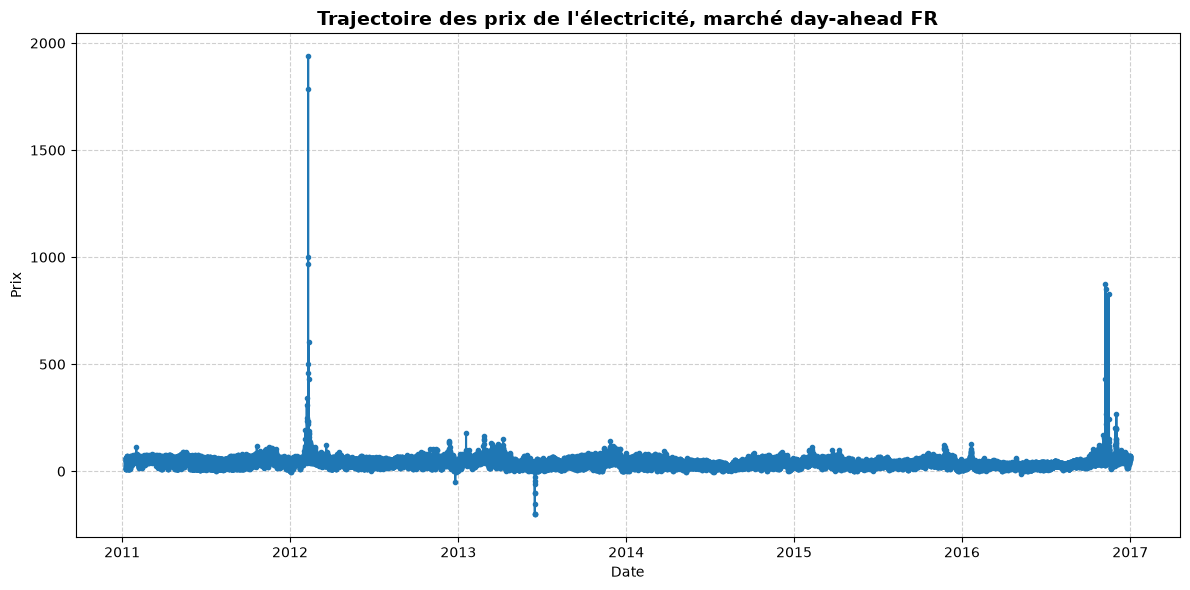

In [8]:
# affichage des donnÃ©es
print(f"Dimensions : {df.shape[0]} lignes x {df.shape[1]} colonnes")
display(df.describe(include="all").T)

def plot_price_trajectory(df, start_date=None, end_date=None):
    """
    Filtre le dataframe des donnÃ©es par date, puis trace la trajectoire des prix
    """
    df_filtered = df.copy()
    df_filtered["Date"] = pd.to_datetime(df_filtered["Date"])
    print(df_filtered.head())
    if start_date:
        df_filtered = df_filtered[df_filtered["Date"]>=pd.to_datetime(start_date)]
        
    if end_date:
        df_filtered = df_filtered[df_filtered["Date"]<=pd.to_datetime(end_date)]

    df_filtered = df_filtered.sort_values("Date")
    
    # crÃ©ation du graphique
    plt.figure(figsize=(12, 6))
    plt.plot(df_filtered["Date"], df_filtered["Prices"], marker=".", linestyle="-", linewidth=1.5)
    plt.title("Trajectoire des prix de l'Ã©lectricitÃ©, marchÃ© day-ahead FR", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Prix")
    plt.grid(True, linestyle='--',alpha=0.6)
    plt.tight_layout()
    plt.show()

plot_price_trajectory(df, start_date="2011-01-09", end_date="2016-12-31")

In [9]:
# --- Visualisation passage heure d'hiver ---

# 2. Conversion de la colonne 'Date' en datetime
df['Date'] = pd.to_datetime(df['Date'])

# Si vos donnÃ©es sont en heure locale franÃ§aise (Paris), on gÃ¨re le fuseau 
# pour intÃ©grer proprement les changements d'heure (23h / 25h par an)
df['Date'] = df['Date'].dt.tz_localize('Europe/Paris', ambiguous='NaT', nonexistent='shift_forward')

# DÃ©finition de la colonne Date comme index
df = df.set_index('Date')

# 3. CrÃ©ation de la plage de rÃ©fÃ©rence idÃ©ale (pas horaire 'h')
full_range = pd.date_range(
    start='2011-01-09 00:00:00',
    end='2016-12-31 23:00:00',
    freq='h',
    tz='Europe/Paris'
)

# 4. Recherche des dates/heures manquantes via la diffÃ©rence d'index
missing_timestamps = full_range.difference(df.index)

print(f"Nombre total d'intervalles horaires manquants : {len(missing_timestamps)}")

if len(missing_timestamps) > 0:
    print("\nExemples de dates manquantes :")
    print(missing_timestamps[:10])
    
    # Optionnel : convertir les timestamps manquants en DataFrame pour les analyser ou les exporter
    df_missing = pd.DataFrame({'Missing_Date': missing_timestamps})
    # df_missing.to_csv('dates_manquantes.csv', index=False)
else:
    print("Aucune date manquante n'a Ã©tÃ© trouvÃ©e sur cette pÃ©riode !")

Nombre total d'intervalles horaires manquants : 12

Exemples de dates manquantes :
DatetimeIndex(['2011-10-30 02:00:00+02:00', '2011-10-30 02:00:00+01:00',
               '2012-10-28 02:00:00+02:00', '2012-10-28 02:00:00+01:00',
               '2013-10-27 02:00:00+02:00', '2013-10-27 02:00:00+01:00',
               '2014-10-26 02:00:00+02:00', '2014-10-26 02:00:00+01:00',
               '2015-10-25 02:00:00+02:00', '2015-10-25 02:00:00+01:00'],
              dtype='datetime64[us, Europe/Paris]', freq=None)


## 3. PrÃ©diction - EPF - Ridge

Nous souhaitons dÃ©sormais appliquer une mÃ©thode EPF standard pour tenter de prÃ©dire les prix du marchÃ©. \
Nous rÃ©alisons une prÃ©diction Ã  l'aide de la mÃ©thode ridge CV. La rÃ©gression Ridge est une rÃ©gressions L2 pÃ©nalisÃ©e Ã  l'aide d'un facteur $\alpha$. La cross validation (CV) permet d'optimiser le choix du facteur $\alpha$. \
On dÃ©coupe les donnÃ©es en 2 Ã  partir de la separation_date (variable du programme).
- Les donnÃ©es antÃ¨rieures Ã  separation_date sont les donnÃ©es d'entraÃ®nement 
- Les donnÃ©es ultÃ©rieures Ã  separation_date sont les donnÃ©es de test\
Ainsi, Ã  partir de la prÃ©vision de production et de demande sur le marchÃ© (les features), nous tentons de dÃ©terminer le prix (la target).


In [10]:
# --- Variables de l'algorithme de rÃ©gression ---
separation_date = "2016-07-01"
features = ["Generation forecast", "System load forecast"]
target = "Prices"

In [11]:
def prediction_ridgecv(df, affichage=False):
    """
    Fonction de prÃ©diction ridge cross validation
    pour le prix de l'Ã©lectricitÃ©
    """

    # paramÃ¨tre de rÃ©gularisation
    alphas = np.logspace(-3,4,50)

    estimator = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2),
        RidgeCV(alphas=alphas, cv=5)
    )

    # sÃ©paration chronologique des donnÃ©es en donnÃ©es test / entrainement
    df = df.sort_values("Date")
    df = df.rename_axis("Date").reset_index()
    train_df = df[df["Date"] < separation_date]
    test_df = df[df["Date"] >= separation_date]

    X_train, y_train = train_df[features], train_df[target]
    X_test, y_test = test_df[features], test_df[target]

    estimator.fit(X_train, y_train)
    df_return = pd.DataFrame({
        "Date": test_df["Date"].to_numpy(),
        "estimation": estimator.predict(X_test),
        "reel": y_test.to_numpy()
    })
    if affichage:
        fig = px.line(
            df_return,
            x="Date",
            y=["estimation", "reel"],
            title="PrÃ©diction du prix de l'Ã©lectricitÃ© vs valeur rÃ©elle",
            labels={"Date": "Date", "value": "Prix de l'Ã©lectricitÃ©", "variable": "SÃ©rie"}
        )
        fig.show()
        
    return df_return


In [12]:
def prediction_ridgecv_rollingwindow():
    # ModÃ¨le RidgeCV rÃ©entraÃ®nÃ© sur une fenÃªtre glissante de 180 jours (donnÃ©es horaires).
    alphas = np.logspace(-3, 4, 50)

    # separation_date = pd.Timestamp("2016-07-01")
    data = df.copy()
    if "Date" not in data.columns:
        if not isinstance(data.index, pd.DatetimeIndex):
            raise ValueError("La date doit Ãªtre une colonne ou un index temporel.")
        data = data.assign(Date=data.index)
    data["Date"] = pd.to_datetime(data["Date"])
    # data = data.sort_values("Date").reset_index(drop=True)
    X = data[features]
    y = data[target]

    test_start = data["Date"].searchsorted(separation_date, side="left")
    if test_start == 0 or test_start == len(data):
        raise ValueError("Il faut des donnÃ©es avant et aprÃ¨s separation_date.")

    rolling_window_size = 30 * 24 * 12 * 5   # 5 ans d'entraÃ®nements
    test_block_size = 30 * 24  # rÃ©entraÃ®nement toutes les 30 jours
    estimator_rolling = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2),
        RidgeCV(alphas=alphas, cv=5),
    )

    predictions = []
    actual_values = []
    actual_dates = []

    for block_start in range(test_start, len(data), test_block_size):
        block_end = min(block_start + test_block_size, len(data))
        train_start = 0 if block_start == test_start else max(0, block_start - rolling_window_size)

        X_train, X_test = X.iloc[train_start:block_start], X.iloc[block_start:block_end]
        y_train, y_test = y.iloc[train_start:block_start], y.iloc[block_start:block_end]

        estimator_rolling.fit(X_train, y_train)
        predictions.extend(estimator_rolling.predict(X_test))
        actual_values.extend(y_test.to_numpy())
        actual_dates.extend(data["Date"].iloc[block_start:block_end])

    df_return = pd.DataFrame({
            "Date": actual_dates,
            "estimation": predictions,
            "reel": actual_values
        })
    return df_return

In [13]:
# --- RÃ©gression ---
"""
On lance la rÃ©gression ridgeCV avec rollingwindow 
"""

# actual_dates, actual_values, predictions = prediction_ridgecv_rollingwindow()

# rolling_dates = pd.DatetimeIndex(actual_dates, name="Date")
# y_pred_rolling = pd.Series(predictions, index=rolling_dates, name="Avec rolling window")
# y_test_rolling = pd.Series(actual_values, index=rolling_dates, name="Valeur rÃ©elle")

df_rollingwindow = prediction_ridgecv_rollingwindow()

In [14]:
# --- Comparaison ridgeCV avec et sans rollingwindow ---

# Comparaison des prÃ©dictions sur les mÃªmes dates

df_baseline = prediction_ridgecv(df)

df_comparaison = (
    df_baseline[["Date", "estimation", "reel"]]
    .rename(columns={"estimation": "Sans rolling window"})
    .set_index("Date")
    .join(
        df_rollingwindow.set_index("Date")["estimation"].rename("Avec rolling window")
    )
)

df_comparaison = df_comparaison.rename(columns={"reel": "Valeur rÃ©elle"})

metrics = pd.DataFrame(
    {
        "MAE": [
            mean_absolute_error(df_comparaison["Valeur rÃ©elle"], df_comparaison["Sans rolling window"]),
            mean_absolute_error(df_comparaison["Valeur rÃ©elle"], df_comparaison["Avec rolling window"]),
        ],
        "RMSE": [
            mean_squared_error(df_comparaison["Valeur rÃ©elle"], df_comparaison["Sans rolling window"]) ** 0.5,
            mean_squared_error(df_comparaison["Valeur rÃ©elle"], df_comparaison["Avec rolling window"]) ** 0.5,
        ],
    },
    index=["Sans rolling window", "Avec rolling window"],
)
display(metrics.round(3))

fig = px.line(
    df_comparaison.reset_index(),
    x=df_comparaison.index,
    y=["Valeur rÃ©elle", "Sans rolling window", "Avec rolling window"],
    title="RidgeCV avec et sans rolling window (mÃªmes dates)",
    labels={"Date": "Date", "value": "Prix de l'Ã©lectricitÃ©", "variable": "SÃ©rie"},
)
fig.show()

,MAE,RMSE
Sans rolling window,11.662,27.675
Avec rolling window,12.017,28.038


Le tableau d'erreur montre que la rÃ©gression ridge avec rolling window est moins prÃ©cise, aussi bien en moyenne (MAE) que pour prÃ©dire les valeurs extrÃªmes (RMSE) que la rÃ©gressions avec fenÃªtre fixe. En effet, la pÃ©riode d'entraÃ®nement telle que codÃ©e ici est plus petite pour la mÃ©thode rolling window. Il faudrait prendre une pÃ©riode d'entraÃ®nement $data\leq separationdate$ fixe, puis chaque mois aprÃ¨s $separationdate$ en plus pour chaque entraÃ®nement. \
Lorsqu'on observe la prÃ©diction avec rolling window cependant, le rÃ©sultat suit plus fidÃ¨lement les fluctuations quotidiennes.

# 4. RÃ©gression Quantile
La spÃ©cificitÃ© de la PEPF est la prÃ©diction d'intervalle. Pour cela, on considÃ¨re un intervalle : $P(x)\in\left[l(x), u(x)\right]$ avec $l(x)$ et $u(x)$ respectivement bornes infÃ©rieures et supÃ©rieures de l'intervalle, $P(x)$ le prix de l'Ã©lectricitÃ© Ã  l'instant $x$. \
Puis en considÃ©rant la fonction quantile de la fonction de distribution cumulÃ©e des prix $Q_\alpha$, on peut choisir un $\alpha\in\left[0,1\right]$ tel que 
 - $l(x) = Q_\frac{\alpha}{2}(x)$
 - $u(x) = Q_{1-\frac{\alpha}{2}}(x)$ 
Pour estimer $Q$, nous utilisons une rÃ©gression quantile. La fonction objectif est la pinball loss:
$$\min_{g\in\mathcal{G}} \mathbb{E}\left[\rho_\beta(Y-g(x))|X=x\right]$$
$\mathcal{G}$ est la classe des rÃ©gresseurs considÃ©rÃ©s. Il en existe diffÃ©rentes : 
 - Quantile Linear Regression : $\mathcal{G}$ est restreint Ã  la classe des rÃ©gresseurs linÃ©aires
 - Quantile Generalized Additive Models  
 - Quantile Random Forests \
 \
Ici, nous nous intÃ©resserons Ã  la Quantile Linear Regression, que nous implÃ©mentons pour notre jeu de donnÃ©es.


In [15]:
alpha = 0.05

In [16]:
def regression_quantile(df):
    """
    RÃ©alise une rÃ©gression quantile linÃ©aire sur les prix de l'Ã©lectricitÃ© et
    calcule un intervalle de prÃ©diction des prix.
    """

    train_df = df[df["Date"] < separation_date]
    test_df = df[df["Date"] >= separation_date]

    # matrice de feature et cibles
    X_train, y_train = train_df[features], train_df[target]
    X_test = test_df[features]

    # choix des quantiles
    q_low = alpha
    q_high = 1-alpha

    # --- ModÃ¨le ---
    # quantile infÃ©rieur
    model_low = QuantileRegressor(quantile=q_low, alpha=0.0, solver="highs")
    model_low.fit(X_train, y_train)
    pred_low = model_low.predict(X_test)

    # quantile supÃ©rieur
    model_high = QuantileRegressor(quantile=q_high, alpha=0.0, solver="highs")
    model_high.fit(X_train, y_train)
    pred_high = model_high.predict(X_test)

    
    # rÃ©sultats
    pred_interval_df = pd.DataFrame(
        {
            "Actual": test_df[target].values,
            "Pred_Low": pred_low,
            "Pred_High": pred_high,
        },
        index=test_df.index,
    )
    return pred_interval_df



In [17]:
pred_interval_df = regression_quantile(df)
pred_interval_df["Date"]=df[df["Date"]>=separation_date]["Date"]
pred_interval_df=pred_interval_df.set_index("Date")

KeyError: 'Date'

In [ ]:
fig = px.line(
    pred_interval_df,
    x=pred_interval_df.index,
    y=["Actual", "Pred_Low", "Pred_High"],
    labels={
        "value": "Prix de l'Ã©lectricitÃ©",
        "index": "Date",
        "variable": "LÃ©gende",
    },
    title=(
        "Comparaison des valeurs rÃ©elles et de l'intervalle de prÃ©diction"
        " (Quantiles)"
    ),
)
fig.update_traces(
    selector=dict(name="Actual"),
    line=dict(color="black", width=2),
    name="Valeur RÃ©elle",
)
fig.update_traces(
    selector=dict(name="Pred_Low"),
    line=dict(color="royalblue", dash="dash", width=1.5),
    name="Intervalle InfÃ©rieur",
)
fig.update_traces(
    selector=dict(name="Pred High"),
    line=dict(color="royalblue", dash="dash", width=1.5),
    name="Intervalle SupÃ©rieur",
)

fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Prix",
    legend_title="ModÃ¨le / RÃ©alitÃ©",
    hovermode="x unified",
)

fig.show()
print(pred_interval_df)

                     Actual   Pred_Low  Pred_High
Date                                             
2016-07-01 00:00:00   29.36  12.343910  60.229570
2016-07-01 01:00:00   24.69   9.890219  52.645510
2016-07-01 02:00:00   23.42   9.573393  52.357620
2016-07-01 03:00:00   21.91   8.421580  47.328411
2016-07-01 04:00:00   20.19   8.551197  44.737318
...                     ...        ...        ...
2016-12-31 19:00:00   69.72  28.979597  87.750301
2016-12-31 20:00:00   57.10  28.005489  86.407287
2016-12-31 21:00:00   54.49  25.978852  83.307118
2016-12-31 22:00:00   54.95  25.247932  81.165609
2016-12-31 23:00:00   61.19  26.646650  89.132954

[4416 rows x 3 columns]


Les intervalles prÃ©dit encadrent effectivement de maniÃ¨re satisfaisante les prix de l'Ã©lectricitÃ©. NÃ©anmoins, on observe que les pics extrÃªmes de prix sont trÃ¨s mal prÃ©dits voir ignorÃ©s par la prÃ©diction. La distribution des prix sur le marchÃ© de l'Ã©lectricitÃ© prÃ©sente des queues de distribution assez lourdes, et donc des pics de prix soudains. On Ã©met l'hypothÃ¨se que ces pics apparaÃ®ssent lors de moment de grandes tensions sur le rÃ©seau (forte demande, et faible production).

In [ ]:
# observons la distribution du prix sur une heure
df_distribution = df.copy()
df_distribution=df_distribution.set_index("Date")
l_df_distribution = [df_distribution[df_distribution.index.hour==i] for i in range(24)]

def plot_price_distribution(i):
    if not isinstance(i, int) or not 0 <= i < len(l_df_distribution):
        raise ValueError(f"i doit Ãªtre un entier entre 0 et {len(l_df_distribution) - 1}")

    prices = l_df_distribution[i]["Prices"].dropna()

    plt.figure(figsize=(10, 6))
    plt.hist(prices, bins=30, edgecolor="black", alpha=0.75)
    plt.title(f"Distribution des prix pour l'heure {i}h")
    plt.xlabel("Prix")
    plt.ylabel("FrÃ©quence")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


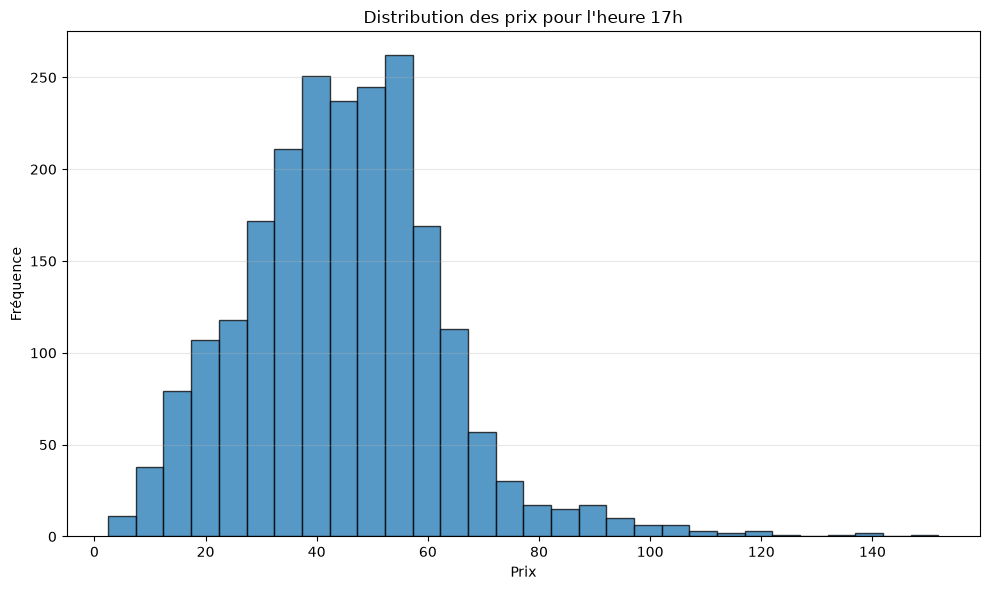

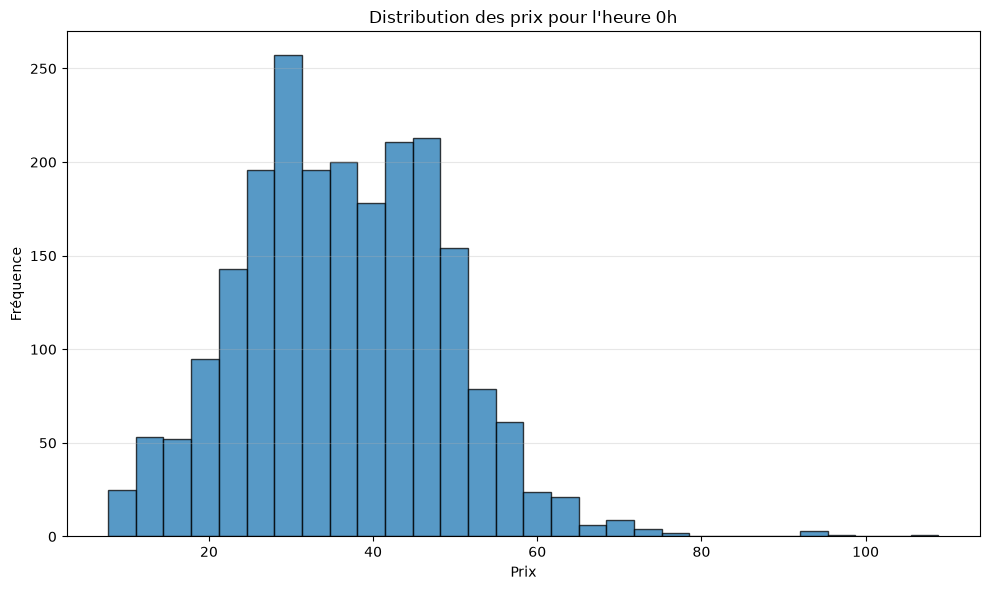

In [ ]:
plot_price_distribution(17)
plot_price_distribution(0)

Pour modÃ©liser ces pics de prix, on considÃ¨re un modÃ¨le hybride. On dÃ©finit un indicateur de tension (lorsque la charge se rapproche de la capacitÃ© max de production). Lorsque cet indicateur franchit un seuil, on augmente la pÃ©nalitÃ© pour les quantiles supÃ©rieurs. 

In [ ]:
penalite = 1

In [ ]:
def modele_hybdride(df):
  
    df["Marge"] = df["Generation forecast"] - df["System load forecast"]
    seuil_critique = df["Marge"].quantile(0.10)
    df["Declenchement tension"] = (df["Marge"] < seuil_critique).astype(int)
    features = [
        "Generation forecast",
        "System load forecast",
        "Marge",
        "Declenchement tension", 
    ]
    target = "Prices"

    train_df = df[df["Date"] < separation_date]
    test_df = df[df["Date"] >= separation_date]

    X_train, y_train = train_df[features], train_df[target]
    X_test, y_test = test_df[features], test_df[target]

    sample_weights = np.ones(len(train_df))
    if "Declenchement tension" in train_df:
        sample_weights[train_df["Declenchement tension"] == 1] = penalite     
    
    # quantiles
    q_low = alpha
    q_high = 1-alpha

    # quantile infÃ©rieur
    model_low = QuantileRegressor(quantile=q_low, alpha=0.0, solver="highs")
    model_low.fit(X_train, y_train)
    pred_low = model_low.predict(X_test)

    # quantile supÃ©rieur
    model_high = QuantileRegressor(quantile=q_high, alpha=0.0, solver="highs")
    model_high.fit(X_train, y_train)
    pred_high = model_high.predict(X_test)
     
    pred_interval_df = pd.DataFrame(
        {
            "Actual": test_df[target].values,
            "Pred_Low": pred_low,
            "Pred_High": pred_high,
        },
        index=test_df.index,
    )
    
    return pred_interval_df



In [ ]:
pred_interval_df_penalite = modele_hybdride(df)

In [ ]:
fig = px.line(
    pred_interval_df,
    x=pred_interval_df.index,
    y=["Actual", "Pred_Low", "Pred_High"],
    labels={
        "value": "Prix de l'Ã©lectricitÃ©",
        "index": "Date",
        "variable": "LÃ©gende",
    },
    title=(
        "Comparaison des valeurs rÃ©elles et de l'intervalle de prÃ©diction"
        " (Quantiles)"
    ),
)
fig.update_traces(
    selector=dict(name="Actual"),
    line=dict(color="black", width=2),
    name="Valeur RÃ©elle",
)
fig.update_traces(
    selector=dict(name="Pred_Low"),
    line=dict(color="royalblue", dash="dash", width=1.5),
    name="Intervalle InfÃ©rieur",
)
fig.update_traces(
    selector=dict(name="Pred High"),
    line=dict(color="royalblue", dash="dash", width=1.5),
    name="Intervalle SupÃ©rieur",
)

fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Prix",
    legend_title="ModÃ¨le / RÃ©alitÃ©",
    hovermode="x unified",
)

fig.show()

Visuellement, la diffÃ©rence ne semble pas significative. Pour quantifier l'efficacitÃ© de cette nouvelle mÃ©thode, nous nous intÃ©ressons Ã  la fonction objectif de la mÃ©thode, Ã  savoir la Pinball Loss.

In [ ]:
def mean_pinball_loss(y_true, y_pred, quantile):
    """
    Calcul la perte moyenne Pinball pour un quantile donnÃ©
    """

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    diff = y_true-y_pred
    loss = np.maximum(quantile*diff, (quantile-1)*diff)
    return np.mean(loss)

In [ ]:
# --- Calcul indicateur Pinball loss pour le modÃ¨le standard ---
# quantile bas
pl_low = mean_pinball_loss(
    y_true=pred_interval_df["Actual"], y_pred=pred_interval_df["Pred_Low"], quantile=0.05
)

# quantile haut
pl_high = mean_pinball_loss(
    y_true=pred_interval_df["Actual"], y_pred=pred_interval_df["Pred_High"], quantile=0.95
)

print(f"Pinball Loss (q=0.05) : {pl_low:.4f}")
print(f"Pinball Loss (q=0.95) : {pl_high:.4f}")

# score global moyen
total_pl = (pl_low + pl_high) / 2
print(f"Pinball Loss Globale de l'intervalle : {total_pl:.4f}")

Pinball Loss (q=0.05) : 1.6306
Pinball Loss (q=0.95) : 2.5276
Pinball Loss Globale de l'intervalle : 2.0791


In [ ]:
# --- Calcul indicateur Pinball loss pour le modÃ¨le hybdride ---
# quantile bas
pl_low = mean_pinball_loss(
    y_true=pred_interval_df["Actual"], y_pred=pred_interval_df_penalite["Pred_Low"], quantile=0.05
)

# quantile haut
pl_high = mean_pinball_loss(
    y_true=pred_interval_df["Actual"], y_pred=pred_interval_df_penalite["Pred_High"], quantile=0.95
)

print(f"Pinball Loss pÃ©nalitÃ© (q=0.05) : {pl_low:.4f}")
print(f"Pinball Loss pÃ©nalitÃ© (q=0.95) : {pl_high:.4f}")

# score global moyen
total_pl = (pl_low + pl_high) / 2
print(f"Pinball Loss Globale pÃ©nalitÃ© de l'intervalle : {total_pl:.4f}")

Pinball Loss pÃ©nalitÃ© (q=0.05) : 1.6469
Pinball Loss pÃ©nalitÃ© (q=0.95) : 2.5918
Pinball Loss Globale pÃ©nalitÃ© de l'intervalle : 2.1193


On observe que la pinball loss est Ã  la fois plus grande pour le quantile infÃ©rieur et supÃ©rieur pour le modÃ¨le hybdride que pour le modÃ¨le standard. NÃ©anmoins, le modÃ¨le hybride prenant en compte les grands pics de prix, au global il semble logique que la fonction objectif soit plus grande pour le modÃ¨le hybride. IntÃ©ressons-nous donc Ã  l'estimation de la Pinball loss conditionnellement Ã  tous les points de forte tension.

In [ ]:
def mean_pinball_loss_conditional(y_true, y_pred, df, quantile):
    """
    Calcul la perte moyenne Pinball pour un quantile donnÃ©
    """
    df_filtered = df[df["Date"]>=separation_date].copy()

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    mask_tension = (df_filtered["Declenchement tension"]==1).to_numpy()
    y_true_tension = y_true[mask_tension]
    y_pred_tension = y_pred[mask_tension]
    diff = y_true_tension-y_pred_tension
    loss = np.maximum(quantile*diff, (quantile-1)*diff)
    return np.mean(loss)


In [ ]:
# --- Calcul indicateur Pinball loss pour le modÃ¨le standard ---
# quantile bas
pl_low = mean_pinball_loss_conditional(
    y_true=pred_interval_df["Actual"], y_pred=pred_interval_df["Pred_Low"], df=df, quantile=0.05
)

# quantile haut
pl_high = mean_pinball_loss_conditional(
    y_true=pred_interval_df["Actual"], y_pred=pred_interval_df["Pred_High"], df=df, quantile=0.95
)

print(f"Pinball Loss (q=0.05) : {pl_low:.4f}")
print(f"Pinball Loss (q=0.95) : {pl_high:.4f}")

# score global moyen
total_pl = (pl_low + pl_high) / 2
print(f"Pinball Loss Globale de l'intervalle : {total_pl:.4f}")

Pinball Loss (q=0.05) : 2.0916
Pinball Loss (q=0.95) : 3.8630
Pinball Loss Globale de l'intervalle : 2.9773


In [ ]:
# --- Calcul indicateur Pinball loss pour le modÃ¨le hybdride ---
# quantile bas
pl_low = mean_pinball_loss_conditional(
    y_true=pred_interval_df["Actual"], y_pred=pred_interval_df_penalite["Pred_Low"], df=df, quantile=0.05
)

# quantile haut
pl_high = mean_pinball_loss_conditional(
    y_true=pred_interval_df["Actual"], y_pred=pred_interval_df_penalite["Pred_High"], df=df, quantile=0.95
)

print(f"Pinball Loss pÃ©nalitÃ© (q=0.05) : {pl_low:.4f}")
print(f"Pinball Loss pÃ©nalitÃ© (q=0.95) : {pl_high:.4f}")

# score global moyen
total_pl = (pl_low + pl_high) / 2
print(f"Pinball Loss Globale pÃ©nalitÃ© de l'intervalle : {total_pl:.4f}")

Pinball Loss pÃ©nalitÃ© (q=0.05) : 2.1479
Pinball Loss pÃ©nalitÃ© (q=0.95) : 3.9931
Pinball Loss Globale pÃ©nalitÃ© de l'intervalle : 3.0705


Une fois de plus, la fonction objectif est plus grande pour le modÃ¨le hybride. Ainsi, l'implÃ©mentation de cette mÃ©thode montre que les informations de production et demande d'Ã©lectricitÃ© ne suffisent pas Ã  expliquer les queues de distribution des prix de l'Ã©lectricitÃ©. Pour aller plus loin, il est donc nÃ©cessaire de prendre en considÃ©ration d'autres facteurs.

# Bibliographie
https://arxiv.org/abs/2405.15359 \
https://www.sciencedirect.com/science/article/pii/S1364032117308808